In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D
import yaml
from pathlib import Path


with open("../plot/plotting_config.yaml") as fp:
    config = yaml.safe_load(fp)

In [2]:
data_folder = "../output/symmetric_area_difference"
figure_folder = "../figures"

In [3]:
# Parameters
data_folder = "../output/symmetric_area_difference/"
figure_folder = "../figures/normal"


In [4]:
Path(figure_folder).mkdir(parents=True, exist_ok=True)

In [5]:
def truncate_colormap(cmap, minval=0.0, maxval=1.0, n=100):
    """
    https://stackoverflow.com/a/18926541/4737417
    by unutbu, CC BY-SA 3.0
    """
    new_cmap = LinearSegmentedColormap.from_list(
        'trunc({n},{a:.2f},{b:.2f})'.format(n=cmap.name, a=minval, b=maxval),
        cmap(np.linspace(minval, maxval, n)))
    return new_cmap

In [6]:
OkabeIto = {
    "orange": "#e69f00",
    "skyblue": "#56b4e9",
    "bluishgreen": "#009e73",
    "yellow": "#f0e442",
    "blue": "#0072b2",
    "vermilion": "#d55e00",
    "reddishpurple": "#cc79a7",
    "black": "#000000",
}

In [7]:
cmap_distr = LinearSegmentedColormap.from_list("districts", ["white", OkabeIto["blue"]], N=25)
cmap_adm10 = LinearSegmentedColormap.from_list("districts", ["white", OkabeIto["yellow"]], N=25)
cmap_road1 = LinearSegmentedColormap.from_list("districts", ["white", OkabeIto["orange"]], N=25)
cmap_road2 = LinearSegmentedColormap.from_list("districts", ["white", OkabeIto["skyblue"]], N=25)


cmap_distr = truncate_colormap(cmap_distr, 0.4, 1)
cmap_adm10 = truncate_colormap(cmap_adm10, 0.4, 1)
cmap_road1 = truncate_colormap(cmap_road1, 0.4, 1)
cmap_road2 = truncate_colormap(cmap_road2, 0.4, 1)

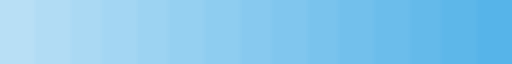

In [8]:
cmap_road2

In [9]:
def agg_fretchet(df):
    temp = df.copy()
    temp["area_symmdiff"] = temp["area_symmdiff"] / 1e6
    return temp.groupby(["run", "resolution", "community_id"])["area_symmdiff"]\
             .mean().reset_index()


In [10]:
fr_distr = pd.read_csv(f"{data_folder}/communities_vs_districts_area_symmdiff.csv")
fr_distr = agg_fretchet(fr_distr)
fr_adm10 = pd.read_csv(f"{data_folder}/communities_vs_neighborhoods_area_symmdiff.csv")
fr_adm10 = agg_fretchet(fr_adm10)
fr_road1 = pd.read_csv(f"{data_folder}/communities_vs_primary_area_symmdiff.csv")
fr_road1 = agg_fretchet(fr_road1)
fr_road2 = pd.read_csv(f"{data_folder}/communities_vs_secondary_area_symmdiff.csv")
fr_road2 = agg_fretchet(fr_road2)

In [11]:
def plot(df, cmap, style="solid", ax=None):
    if ax:
        fig = ax.get_figure()
    else:
        fig, ax = plt.subplots(figsize=(6, 6))
    sns.lineplot(
        data=df.groupby(["resolution", "run"])["area_symmdiff"].mean().reset_index(),
        x="resolution", y="area_symmdiff",
        hue="run",
        linestyle=style,
        ax=ax,
        legend=False,
        palette=cmap
    )
    ax.set_xlabel("Resolution")
    ax.set_ylabel("Area symmetric difference ($km^2$)")

    return fig, ax

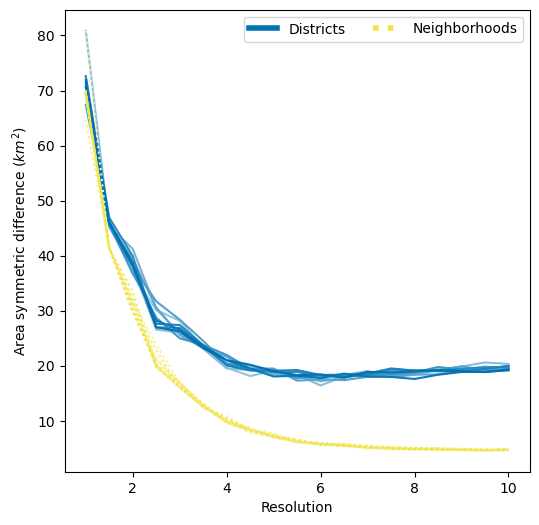

In [12]:
fadm, aadm = plot(fr_distr, cmap_distr)
plot(fr_adm10, cmap_adm10, style="dotted", ax=aadm)

legend_elements = []
labels = ["Districts", "Neighborhoods"]
styles = ["solid", "dotted"]
lcolors = [OkabeIto["blue"], OkabeIto["yellow"]]
for l, c, s in zip(labels, lcolors, styles):
    elem = Line2D([0], [0], color=c, lw=4, linestyle=s, label=l)
    legend_elements.append(elem)

aadm.legend(handles=legend_elements, ncols=2)

for i in config["formats"]:
    fadm.savefig(f"{figure_folder}/area_symmdiff_administrative.{i}",
                 dpi=300, facecolor="white", #bbox_inches="tight",
                 metadata=config["metadata"])

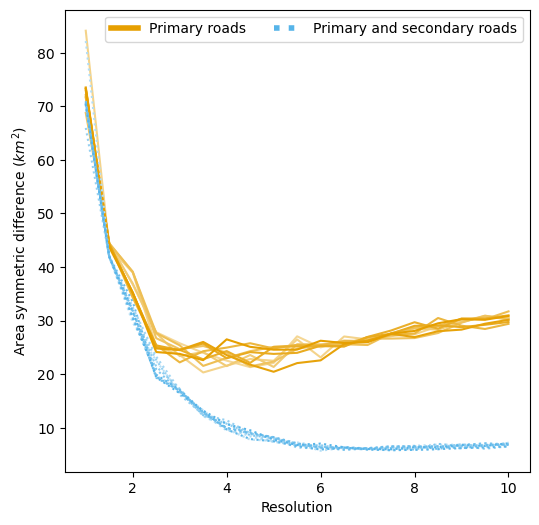

In [13]:
fbar, abar = plot(fr_road1, cmap_road1)
plot(fr_road2, cmap_road2, style="dotted", ax=abar)

legend_elements = []
labels = ["Primary roads", "Primary and secondary roads"]
styles = ["solid", "dotted"]
lcolors = [OkabeIto["orange"], OkabeIto["skyblue"]]
for l, c, s in zip(labels, lcolors, styles):
    elem = Line2D([0], [0], color=c, lw=4, linestyle=s, label=l)
    legend_elements.append(elem)

abar.legend(handles=legend_elements, ncols=2)

for i in config["formats"]:
    fbar.savefig(f"{figure_folder}/area_symmdiff_barriers.{i}",
                 dpi=300, facecolor="white", #bbox_inches="tight",
                 metadata=config["metadata"])